How are in-demand skills trending for Data Analysts?

Methology

1.Aggregate skil counts monthly 
2.Re-analyze based on percentage of total jobs
3.Plot the monthly skill demand 

In [1]:

import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

df = pd.read_csv('indian_tech_jobs_2026.csv')

In [2]:
df_IND = df[(df['job_title'] == 'Data Analyst') & (df['scraped_city'])].copy()

C:\Users\Admin\AppData\Local\Temp\ipykernel_8924\2553829421.py:1: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  df_IND = df[(df['job_title'] == 'Data Analyst') & (df['scraped_city'])].copy()


In [3]:
df_IND['scraped_at'] = pd.to_datetime(df_IND['scraped_at'])
df_IND['job_posted_month_no'] = df_IND['scraped_at'].dt.month


In [ ]:
df_IND = df.dropna(subset=['skills_required']).copy()

df_IND['skills_list'] = df_IND['skills_required'].apply(
    lambda x: [skill.strip() for skill in x.split(',') if skill.strip() not in ['', 'Not Available']]
)

In [5]:
df_IND_explode = df_IND.explode('skills_list')
df_IND['skills_list'] = df_IND['skills_required'].str.split(', ')
df_IND_explode['skills_list'] = df_IND_explode['skills_list'].str.strip

In [ ]:
import pandas as pd


df_IND = df[df['job_title'] == 'Data Analyst'].copy()

df_IND['scraped_at'] = pd.to_datetime(df_IND['scraped_at'])
df_IND['job_posted_date'] = df_IND['scraped_at'] - pd.to_timedelta(df_IND['days_since_posted'], unit='D')
df_IND['job_posted_month_no'] = df_IND['job_posted_date'].dt.month

df_IND = df_IND[df_IND['skills_required'].notna() & (df_IND['skills_required'] != 'Not Available')].copy()
df_IND['skills_list'] = df_IND['skills_required'].str.split(', ')

df_IND_explode = df_IND.explode('skills_list')
df_IND_explode['skills_list'] = df_IND_explode['skills_list'].str.strip()

top_10_skills = df_IND_explode['skills_list'].value_counts().head(10).index.tolist()
df_IND_top10 = df_IND_explode[df_IND_explode['skills_list'].isin(top_10_skills)]

df_pivot = df_IND_top10.pivot_table(
    index='job_posted_month_no', 
    columns='skills_list', 
    aggfunc='size', 
    fill_value=0
)

df_pivot.loc['Total'] = df_pivot.sum()

df_pivot = df_pivot[df_pivot.loc['Total'].sort_values(ascending=False).index]

df_pivot = df_pivot.drop('Total')
df_pivot

skills_list,Data analysis,Data Analyst,SQL,Data,Analytical,Power Bi,Analytics,data analysis,power bi,Data Analytics
job_posted_month_no,,,,,,,,,,
5,130,118,69,69,70,34,38,46,46,25
6,34,16,36,27,7,33,26,10,6,25


In [ ]:
Data_analyst_total = df_IND.groupby('job_posted_month_no').size()

df_IND_DA_perc = df_pivot.div(Data_analyst_total, axis=0) * 100

df_IND_DA_perc = df_IND_DA_perc[df_IND_DA_perc.sum().sort_values(ascending=False).index]

df_IND_DA_perc.head()

skills_list,Data analysis,SQL,Data Analyst,Data,Power Bi,Analytics,Data Analytics,Analytical,data analysis,power bi
job_posted_month_no,,,,,,,,,,
5,42.207792,22.402597,38.311688,22.402597,11.038961,12.337662,8.116883,22.727273,14.935065,14.935065
6,36.170213,38.297872,17.021277,28.723404,35.106383,27.659574,26.595745,7.446809,10.638298,6.382979


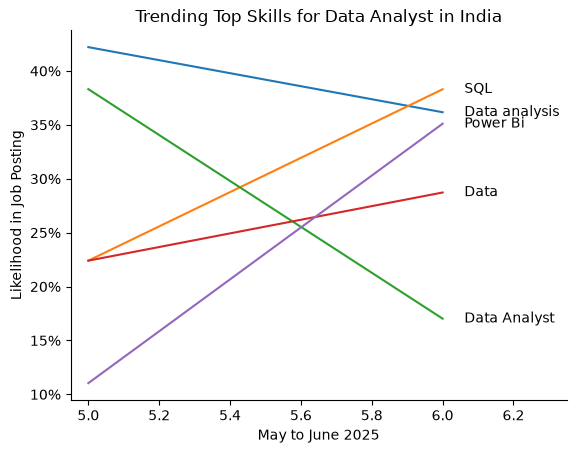

In [ ]:
df_plot = df_IND_DA_perc.iloc[:, :5]

sns.lineplot(data=df_plot, dashes=False, palette='tab10')
sns.despine()

plt.title('Trending Top Skills for Data Analyst in India')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('May to June 2025')
plt.legend().remove()

last_x = len(df_plot) - 1 if isinstance(df_plot.index[0], str) else df_plot.index[-1]
x_pos = last_x + 0.05  




for i in range(5):
    plt.text(x_pos, df_plot.iloc[-1, i], f" {df_plot.columns[i]}", va='center')

plt.xlim(right=x_pos + 0.3) 
plt.show()